In [32]:
from pathlib import Path
import polars as pl
from polars import selectors as sc

DATA_DIR = Path.cwd().parent / "data" / "data-processed" / "normalized_data.csv"

df = pl.read_csv(str(DATA_DIR))
train = df.filter(pl.col("conjunto") == "train").select(sc.numeric())

#verificamos que ya esta normalizado
print(train.mean())
print(train.std())

shape: (1, 7)
┌──────────────┬─────────────┬─────────────┬─────────────┬─────────────┬─────────────┬─────────────┐
│ global_activ ┆ global_reac ┆ voltage     ┆ global_inte ┆ sub_meterin ┆ sub_meterin ┆ sub_meterin │
│ e_power      ┆ tive_power  ┆ ---         ┆ nsity       ┆ g_1         ┆ g_2         ┆ g_3         │
│ ---          ┆ ---         ┆ f64         ┆ ---         ┆ ---         ┆ ---         ┆ ---         │
│ f64          ┆ f64         ┆             ┆ f64         ┆ f64         ┆ f64         ┆ f64         │
╞══════════════╪═════════════╪═════════════╪═════════════╪═════════════╪═════════════╪═════════════╡
│ -3.8400e-18  ┆ -3.7625e-17 ┆ -4.4575e-15 ┆ -1.2275e-16 ┆ -3.4478e-18 ┆ 1.0850e-17  ┆ -2.2364e-18 │
└──────────────┴─────────────┴─────────────┴─────────────┴─────────────┴─────────────┴─────────────┘
shape: (1, 7)
┌──────────────┬──────────────┬─────────┬──────────────┬──────────────┬──────────────┬─────────────┐
│ global_activ ┆ global_react ┆ voltage ┆ global_inten ┆ sub_me

In [33]:
from sklearn.decomposition import PCA
import numpy as np
SEED = 2026

pca = PCA(n_components=None, svd_solver="auto", random_state=SEED)
pca.fit(train)

var = pca.explained_variance_
var_ratio = pca.explained_variance_ratio_
print(f"var: {var}, var_ratio: {var_ratio}")

var_cum = np.cumsum(var_ratio)


for i, (v, a) in enumerate(zip(var, var_cum), start=1): 
    print(f"PC{i}: {v:.3f} acumulada {a:.3f}")

var: [3.22643951e+00 9.88979920e-01 9.34371586e-01 8.34907277e-01
 7.87499702e-01 2.27109381e-01 6.96892114e-04], var_ratio: [4.60919649e-01 1.41282760e-01 1.33481574e-01 1.19272395e-01
 1.12499889e-01 3.24441775e-02 9.95559555e-05]
PC1: 3.226 acumulada 0.461
PC2: 0.989 acumulada 0.602
PC3: 0.934 acumulada 0.736
PC4: 0.835 acumulada 0.855
PC5: 0.787 acumulada 0.967
PC6: 0.227 acumulada 1.000
PC7: 0.001 acumulada 1.000


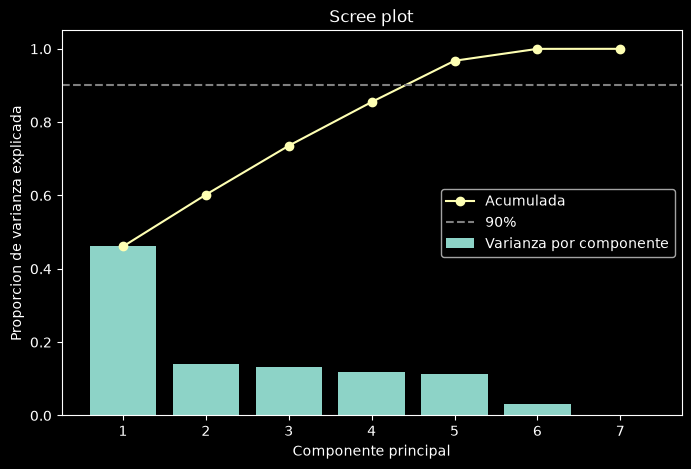

In [34]:
#creamos la scree plot para ver cuales eigenvectores nos dan mucha explicacion de varianza
import matplotlib.pyplot as plt


k = np.arange(1, len(var) + 1)

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(k, var_ratio, label="Varianza por componente")
ax.plot(k, var_cum, marker="o", color="C1", label="Acumulada")
#ls de linestyle
ax.axhline(0.90,ls="--", color="gray", label="90%")
ax.set_xticks(k)
ax.set_xlabel("Componente principal")
ax.set_ylabel("Proporcion de varianza explicada")
ax.set_title("Scree plot")
ax.legend()
plt.savefig(str(Path.cwd().parent / "graphs" / "scree_plot.png"), dpi =500, bbox_inches="tight")
plt.show()

In [35]:
#primero elegimos los componentes principales que nos expliquen el 90% de la varianza total
k_elegido = int(np.argmax(var_cum >= 0.90) + 1) #le sumamos uno solo para la impresion
print(f"Componentes para 90%: {k_elegido}")
#vi que habia otro criterio llamado kaiser
# print(f"Kaise: {int((pca.explained_variance_ > 1).sum())}")


Componentes para 90%: 5


Si multiplicamos la raiz del eigenvalor por el peso asignado a la variable para es componente principal, obtendriamos la correlacion de la variable con el componente principal 
El componente principal es la combinación lineal

$$Z_k = X v_k = \sum_j v_{jk} X_j$$

$$X v_k = \begin{pmatrix} | & | & & | \\ X_1 & X_2 & \cdots & X_p \\ | & | & & | \end{pmatrix} \begin{pmatrix} v_{1k} \\ v_{2k} \\ \vdots \\ v_{pk}\end{pmatrix} = v_{1k}X_1 + v_{2k}X_2 + \dots + v_{pk}X_p$$

**1. Varianza del componente.**

$$\text{Var}(Z_k) = v_k^\top \Sigma\, v_k = v_k^\top (\lambda_k v_k) = \lambda_k$$

porque **v**ₖ tiene norma 1. Por eso la desviación estándar del componente es √λₖ.

**2. Covarianza entre la variable j y el componente.**

$Z_k$ es el componente
$$\text{Cov}(X_j, Z_k) = \text{Cov}\Big(X_j, \sum_i v_{ik}X_i\Big) = \sum_{i=1}^{p} v_{ik}\,\text{Cov}(X_j, X_i)$$
Cov(Xⱼ, Xᵢ) es la entrada Σⱼᵢ de la matriz de covarianza, así que

$$\text{Cov}(X_j, Z_k) = \sum_i \Sigma_{ji}\, v_{ik}$$

Esto es exactamente la fórmula de la **entrada j del vector Σvₖ**: tomas la fila _j_ de Σ y la multiplicas por el vector **v**ₖ, i.e. vector por vector.

$$\text{Cov}(X_j, Z_k) = (\Sigma v_k)_j$$
Asi tenemos el eigenvalor por la jesima entrada del vector propio
$$\text{Cov}(X_j, Z_k) = e_j^\top \Sigma\, v_k = e_j^\top(\lambda_k v_k) = \lambda_k\, v_{jk}$$


Aquí **e**ⱼ es el vector que selecciona la variable _j_. Este es el paso clave: como **v**ₖ es eigenvector, Σ**v**ₖ no es un vector cualquiera, sino el mismo **v**ₖ escalado por λₖ.

**3. Correlación.** Se divide la covarianza entre las dos desviaciones estándar:

$$\text{Corr}(X_j, Z_k) = \frac{\lambda_k v_{jk}}{\sigma_j \sqrt{\lambda_k}} = \frac{v_{jk}\sqrt{\lambda_k}}{\sigma_j}$$

**4. Si las variables están estandarizadas** (PCA sobre la matriz de correlaciones), entonces σⱼ = 1 y queda:

$$\text{Corr}(X_j, Z_k) = v_{jk}\sqrt{\lambda_k}$$

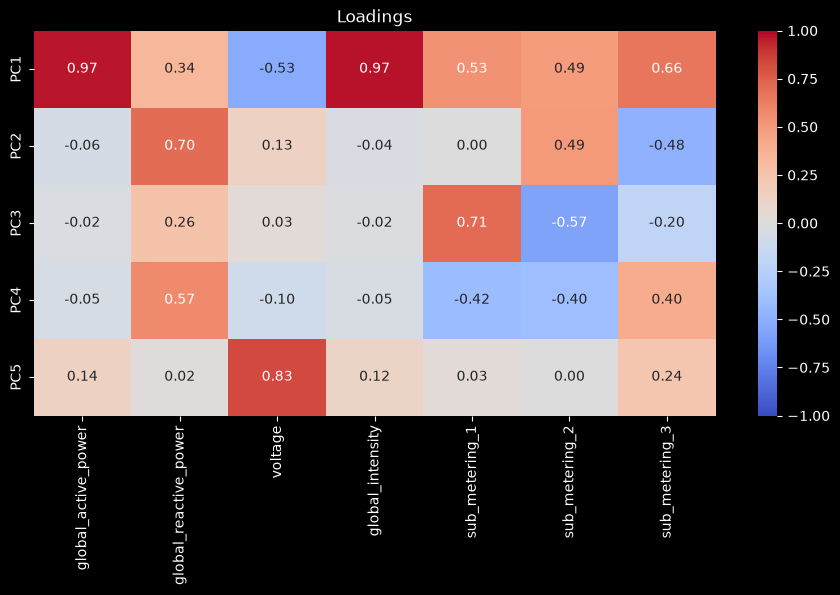

In [39]:
import seaborn as sns
loadings = pca.components_[:k_elegido].T * np.sqrt(pca.explained_variance_[:k_elegido])

nombres_pc = [f"PC{i}" for i in range(1, k_elegido  + 1)]
plt.figure(figsize=(1.6 * k_elegido + 3, 5))
sns.heatmap(loadings.T, annot=True, fmt=".2f", cmap="coolwarm", center = 0, 
            vmin=-1, vmax=1, xticklabels=train.columns, yticklabels=nombres_pc)

plt.title("Loadings")
plt.show()


tendriamos que ir agrupando por cada componente principal algunas variables, un criterio comun es usar >= 0.5, para que sea parte de ese componente principal